In [15]:
import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.utils.class_weight import compute_class_weight

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
import os

model_path = os.path.join("models", "model.keras")

In [18]:
zip_path = "/content/drive/MyDrive/chest_xray.zip"

In [20]:
import os

print(os.path.exists('/content/drive/MyDrive/chest_xray.zip'))

False


In [22]:
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.zip'):
            print(os.path.join(root, file))

/content/drive/MyDrive/archive (2).zip
/content/drive/MyDrive/archive (7).zip
/content/drive/MyDrive/archive (4).zip
/content/drive/MyDrive/archive (8).zip


In [23]:
zip_path = "/content/drive/MyDrive/archive (4).zip"

In [25]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/archive (4).zip'
extract_path = '/content'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)


print(os.listdir(extract_path))

['.config', 'chest_xray', 'drive', 'sample_data']


In [26]:
dataset_path = "/content/chest_xray/chest_xray"

train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

In [27]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,

    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=True,
    fill_mode='nearest',

    validation_split=0.20
)

In [28]:
train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    shuffle=True,
    seed=42
)

Found 4173 images belonging to 2 classes.


In [29]:
validation_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False,
    seed=42
)

Found 1043 images belonging to 2 classes.


In [30]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 624 images belonging to 2 classes.


In [31]:
print("Training Images :", train_generator.samples)
print("Validation Images :", validation_generator.samples)
print("Test Images :", test_generator.samples)

Training Images : 4173
Validation Images : 1043
Test Images : 624


In [33]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(1.9445479962721341), 1: np.float64(0.6730645161290323)}


In [34]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)
x = Dropout(0.4)(x)

x = Dense(256, activation="relu")(x)

x = BatchNormalization()(x)
x = Dropout(0.3)(x)

output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [35]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [36]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/LungDisease/best_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

In [37]:
base_model.trainable = False

In [38]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history1 = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=5,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.6920 - loss: 0.5860
Epoch 1: val_loss improved from None to 0.46217, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 1175s 9s/step - accuracy: 0.7599 - loss: 0.4473 - val_accuracy: 0.7910 - val_loss: 0.4622 - learning_rate: 1.0000e-04
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8281 - loss: 0.3186
Epoch 2: val_loss improved from 0.46217 to 0.34469, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 1105s 8s/step - accuracy: 0.8385 - loss: 0.3083 - val_accuracy: 0.8686 - val_loss: 0.3447 - learning_rate: 1.0000e-04
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8534 - loss: 0.2813
Epoch 3: val_loss improved from 0.34469 to 

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False

print("Trainable layers:")
print(sum([layer.trainable for layer in model.layers]))

Trainable layers:
57


In [ ]:
history2 = model.fit(
    train_generator,
    validation_data=validation_generator,
    initial_epoch=5,
    epochs=17,          # 12 more epochs (6–17)
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Epoch 6/17
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8926 - loss: 0.2458
Epoch 6: val_loss did not improve from 0.22795
131/131 ━━━━━━━━━━━━━━━━━━━━ 1217s 9s/step - accuracy: 0.8919 - loss: 0.2421 - val_accuracy: 0.9003 - val_loss: 0.2648 - learning_rate: 1.0000e-05
Epoch 7/17
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.8981 - loss: 0.2274
Epoch 7: val_loss did not improve from 0.22795
131/131 ━━━━━━━━━━━━━━━━━━━━ 1226s 9s/step - accuracy: 0.8979 - loss: 0.2227 - val_accuracy: 0.9137 - val_loss: 0.2583 - learning_rate: 1.0000e-05
Epoch 8/17
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8993 - loss: 0.2161
Epoch 8: val_loss improved from 0.22795 to 0.22457, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 8: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 1181s 9s/step - accuracy: 0.8998 - loss: 0.2124 - val_accuracy: 0.9156 - val_loss: 0.2246 - learning_rate: 1.0000e-05
Epo

In [39]:
history3 = model.fit(
    train_generator,
    validation_data=validation_generator,
    initial_epoch=17,     # continue from where you stopped
    epochs=25,             # new target — adjust as needed
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Epoch 18/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6718 - loss: 0.6067
Epoch 18: val_loss improved from None to 0.56937, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 18: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 999s 7s/step - accuracy: 0.7450 - loss: 0.4674 - val_accuracy: 0.7095 - val_loss: 0.5694 - learning_rate: 1.0000e-04
Epoch 19/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8268 - loss: 0.3310
Epoch 19: val_loss improved from 0.56937 to 0.37792, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 19: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 982s 8s/step - accuracy: 0.8426 - loss: 0.3091 - val_accuracy: 0.8514 - val_loss: 0.3779 - learning_rate: 1.0000e-04
Epoch 20/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8631 - loss: 0.2805
Epoch 20: val_loss improved from 0.

In [40]:
history4 = model.fit(
    train_generator,
    validation_data=validation_generator,
    initial_epoch=25,     # continue from where you stopped
    epochs=28,             # new target — adjust as needed
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Epoch 26/28
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9149 - loss: 0.2080
Epoch 26: val_loss improved from 0.20613 to 0.19994, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 26: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 979s 7s/step - accuracy: 0.9180 - loss: 0.2049 - val_accuracy: 0.9214 - val_loss: 0.1999 - learning_rate: 1.0000e-04
Epoch 27/28
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9159 - loss: 0.1981
Epoch 27: val_loss improved from 0.19994 to 0.18184, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 27: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 979s 7s/step - accuracy: 0.9188 - loss: 0.1954 - val_accuracy: 0.9377 - val_loss: 0.1818 - learning_rate: 1.0000e-04
Epoch 28/28
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9272 - loss: 0.1618
Epoch 28: val_loss did not impro

In [42]:
history5 = model.fit(
    train_generator,
    validation_data=validation_generator,
    initial_epoch=28,     # continue from where you stopped
    epochs=30,             # new target — adjust as needed
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Epoch 29/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9280 - loss: 0.1687
Epoch 29: val_loss improved from 0.18184 to 0.17547, saving model to /content/drive/MyDrive/LungDisease/best_model.keras

Epoch 29: finished saving model to /content/drive/MyDrive/LungDisease/best_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 991s 8s/step - accuracy: 0.9276 - loss: 0.1690 - val_accuracy: 0.9386 - val_loss: 0.1755 - learning_rate: 1.0000e-04
Epoch 30/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9221 - loss: 0.1949
Epoch 30: val_loss did not improve from 0.17547
131/131 ━━━━━━━━━━━━━━━━━━━━ 1003s 8s/step - accuracy: 0.9317 - loss: 0.1756 - val_accuracy: 0.9300 - val_loss: 0.1801 - learning_rate: 1.0000e-04


In [43]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

20/20 ━━━━━━━━━━━━━━━━━━━━ 110s 5s/step - accuracy: 0.8974 - loss: 0.2443
Test Accuracy: 0.8974359035491943
Test Loss: 0.24430333077907562


In [45]:
model.save("/content/drive/MyDrive/LungDisease/final_model.keras")


In [46]:
from tensorflow.keras.models import load_model

best_model = load_model("/content/drive/MyDrive/LungDisease/best_model.keras")

loss, acc = best_model.evaluate(test_generator)

print(acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 119s 5s/step - accuracy: 0.8974 - loss: 0.2443
0.8974359035491943


In [ ]:
train_acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']

train_loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

epochs = range(1, len(train_acc) + 1)

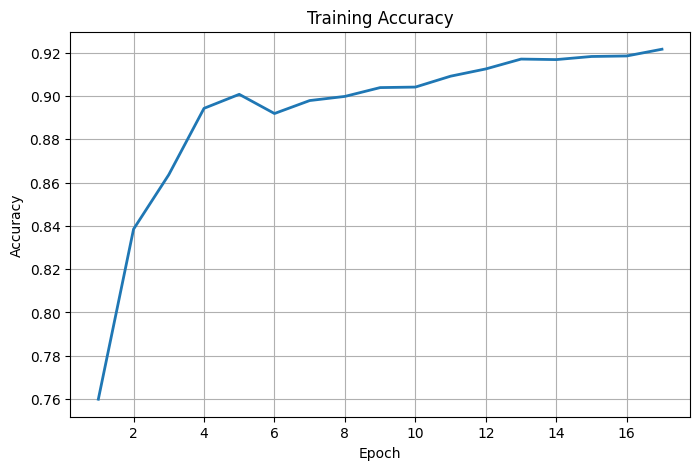

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(epochs, train_acc, linewidth=2)
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

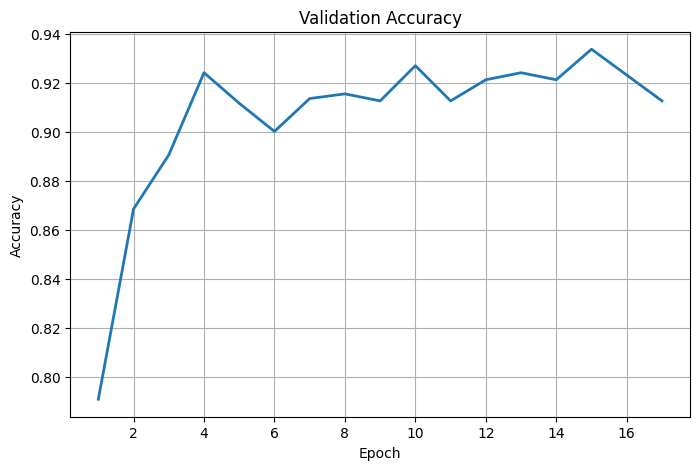

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(epochs, val_acc, linewidth=2)
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

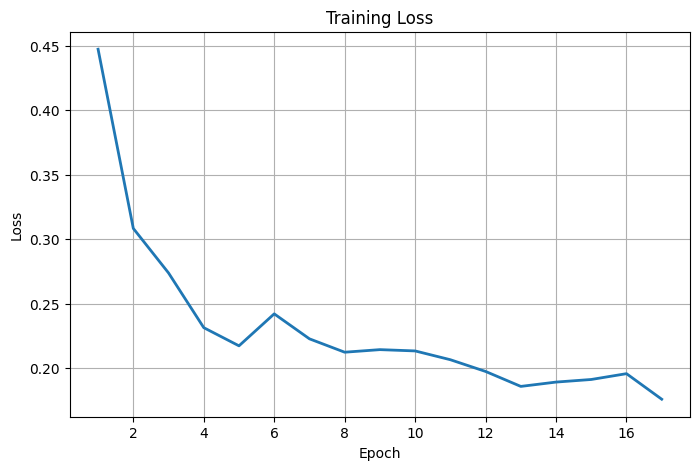

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(epochs, train_loss, linewidth=2)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

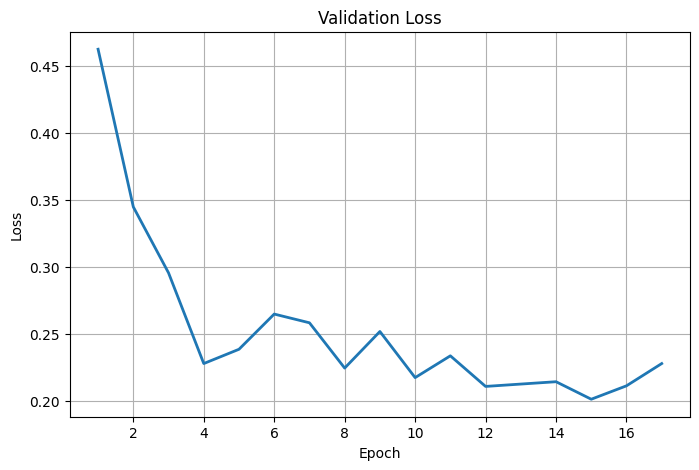

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(epochs, val_loss, linewidth=2)
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

test_generator.reset()

pred_probs = model.predict(test_generator)

pred_classes = (pred_probs > 0.5).astype(int).flatten()

true_classes = test_generator.classes

20/20 ━━━━━━━━━━━━━━━━━━━━ 129s 6s/step


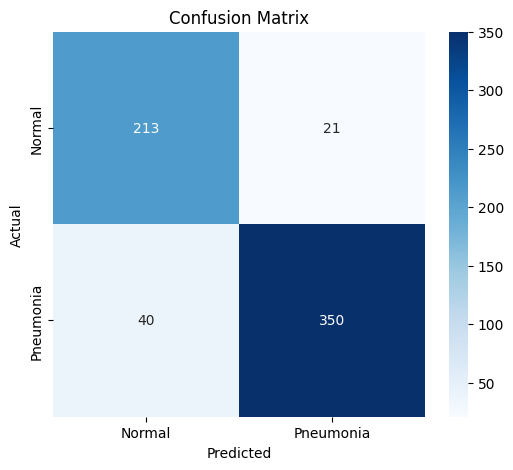

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(true_classes, pred_classes)

plt.figure(figsize=(6,5))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Normal','Pneumonia'],
            yticklabels=['Normal','Pneumonia'])

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    true_classes,
    pred_classes,
    target_names=['Normal','Pneumonia']
))

              precision    recall  f1-score   support

      Normal       0.84      0.91      0.87       234
   Pneumonia       0.94      0.90      0.92       390

    accuracy                           0.90       624
   macro avg       0.89      0.90      0.90       624
weighted avg       0.91      0.90      0.90       624



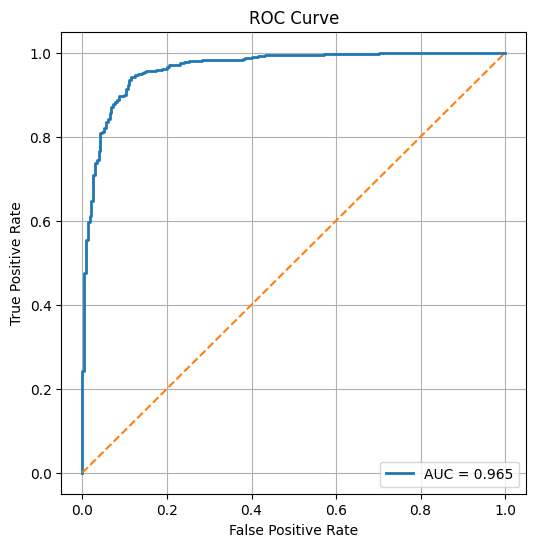

In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(true_classes, pred_probs)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, linewidth=2, label='AUC = %0.3f' % roc_auc)
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
model.save("/content/drive/MyDrive/LungDisease/final_model.keras")

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [ ]:
for layer in model.layers:
    print(layer.name)

input_layer
zero_padding2d
conv1_conv
conv1_bn
conv1_relu
zero_padding2d_1
pool1
conv2_block1_0_bn
conv2_block1_0_relu
conv2_block1_1_conv
conv2_block1_1_bn
conv2_block1_1_relu
conv2_block1_2_conv
conv2_block1_concat
conv2_block2_0_bn
conv2_block2_0_relu
conv2_block2_1_conv
conv2_block2_1_bn
conv2_block2_1_relu
conv2_block2_2_conv
conv2_block2_concat
conv2_block3_0_bn
conv2_block3_0_relu
conv2_block3_1_conv
conv2_block3_1_bn
conv2_block3_1_relu
conv2_block3_2_conv
conv2_block3_concat
conv2_block4_0_bn
conv2_block4_0_relu
conv2_block4_1_conv
conv2_block4_1_bn
conv2_block4_1_relu
conv2_block4_2_conv
conv2_block4_concat
conv2_block5_0_bn
conv2_block5_0_relu
conv2_block5_1_conv
conv2_block5_1_bn
conv2_block5_1_relu
conv2_block5_2_conv
conv2_block5_concat
conv2_block6_0_bn
conv2_block6_0_relu
conv2_block6_1_conv
conv2_block6_1_bn
conv2_block6_1_relu
conv2_block6_2_conv
conv2_block6_concat
pool2_bn
pool2_relu
pool2_conv
pool2_pool
conv3_block1_0_bn
conv3_block1_0_relu
conv3_block1_1_conv
con

Last Conv Layer : conv5_block16_2_conv


Saving demo1.png to demo1 (1).png
Uploaded Image : demo1 (1).png
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
--------------------------------
Prediction : PNEUMONIA
Confidence : 66.22 %
--------------------------------


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


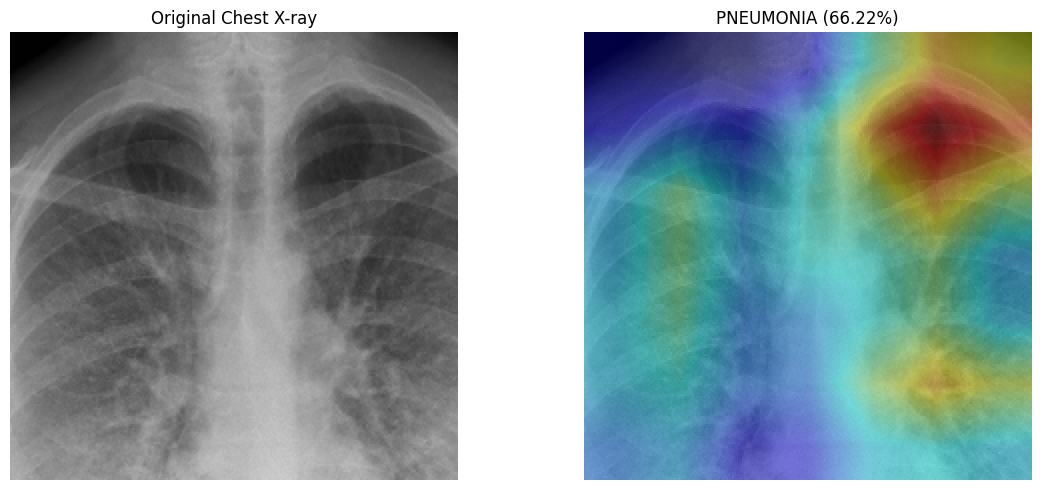

Final Prediction : PNEUMONIA
Confidence : 66.22 %


In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from google.colab import files

# ======================================================
# LOAD MODEL
# ======================================================

model = load_model("/content/drive/MyDrive/LungDisease/final_model.keras")

IMG_SIZE = (224,224)

# ======================================================
# FIND LAST CONV LAYER AUTOMATICALLY
# ======================================================

last_conv_layer_name = None

for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer :", last_conv_layer_name)

# ======================================================
# UPLOAD IMAGE
# ======================================================

uploaded = files.upload()

img_path = list(uploaded.keys())[0]

print("Uploaded Image :", img_path)

# ======================================================
# PREPROCESS IMAGE
# ======================================================

img = image.load_img(
    img_path,
    target_size=IMG_SIZE
)

img_array = image.img_to_array(img)

original_image = img_array.astype("uint8")

img_array = np.expand_dims(img_array, axis=0)

# SAME PREPROCESSING AS TRAINING
img_array = img_array / 255.0

# ======================================================
# PREDICTION
# ======================================================

prediction = model.predict(img_array)[0][0]

if prediction > 0.5:
    label = "PNEUMONIA"
    confidence = prediction * 100
else:
    label = "NORMAL"
    confidence = (1-prediction) * 100

print("--------------------------------")
print("Prediction :", label)
print("Confidence :", round(confidence,2),"%")
print("--------------------------------")

# ======================================================
# GRAD MODEL
# ======================================================

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(last_conv_layer_name).output,
        model.output
    ]
)

# ======================================================
# COMPUTE GRAD-CAM
# ======================================================

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(img_array)

    loss = predictions[:,0]

grads = tape.gradient(loss, conv_outputs)

pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

conv_outputs = conv_outputs[0]

heatmap = tf.reduce_sum(
    pooled_grads * conv_outputs,
    axis=-1
)

heatmap = tf.maximum(heatmap,0)

heatmap /= tf.reduce_max(heatmap)

heatmap = heatmap.numpy()

# ======================================================
# CREATE HEATMAP
# ======================================================

heatmap = cv2.resize(
    heatmap,
    (IMG_SIZE[1], IMG_SIZE[0])
)

heatmap = np.uint8(255 * heatmap)

heatmap = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)

original_bgr = cv2.cvtColor(
    original_image,
    cv2.COLOR_RGB2BGR
)

overlay = cv2.addWeighted(
    original_bgr,
    0.6,
    heatmap,
    0.4,
    0
)

overlay = cv2.cvtColor(
    overlay,
    cv2.COLOR_BGR2RGB
)

# ======================================================
# DISPLAY
# ======================================================

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(original_image.astype("uint8"))
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(overlay)
plt.title(f"{label} ({confidence:.2f}%)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Final Prediction :", label)
print("Confidence :", round(confidence,2),"%")

Last Conv Layer : conv5_block16_2_conv


Saving img3.jpg to img3.jpg


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


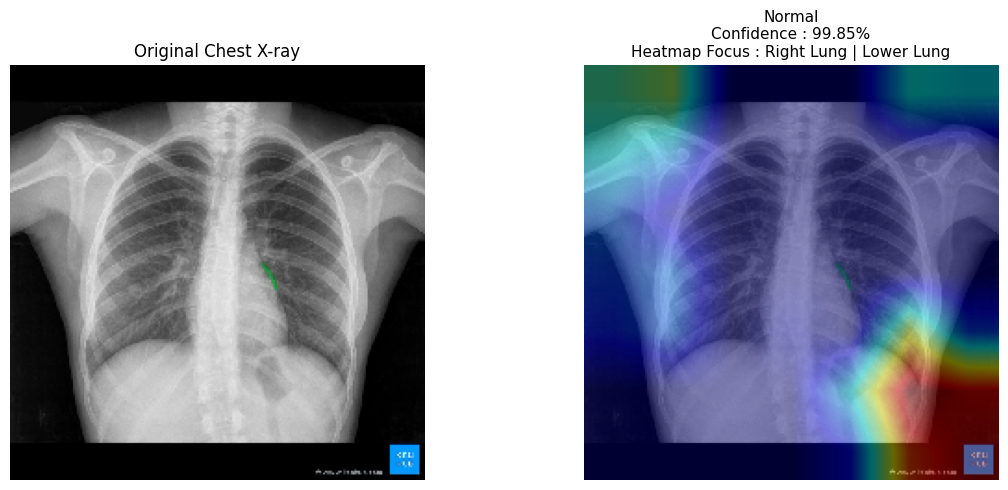

          LUNG DISEASE REPORT
Prediction        : Normal
Confidence Score  : 99.85%
Risk Level        : High
Heatmap Focus     : Right Lung | Lower Lung


In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from google.colab import files

# ==========================================================
# LOAD MODEL
# ==========================================================

model = load_model("/content/drive/MyDrive/LungDisease/final_model.keras")

IMG_SIZE = (224,224)

# ==========================================================
# FIND LAST CONV LAYER
# ==========================================================

last_conv_layer_name = None

for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer :", last_conv_layer_name)

# ==========================================================
# UPLOAD IMAGE
# ==========================================================

uploaded = files.upload()

img_path = list(uploaded.keys())[0]

# ==========================================================
# PREPROCESS IMAGE
# ==========================================================

img = image.load_img(img_path, target_size=IMG_SIZE)

img_array = image.img_to_array(img)

original_image = img_array.astype("uint8")

img_array = np.expand_dims(img_array, axis=0)

# Same preprocessing as training
img_array = img_array / 255.0

# ==========================================================
# PREDICTION
# ==========================================================

prediction = model.predict(img_array, verbose=0)[0][0]

if prediction > 0.5:
    label = "Pneumonia"
    confidence = prediction * 100
else:
    label = "Normal"
    confidence = (1-prediction) * 100

# ==========================================================
# GRAD-CAM
# ==========================================================

grad_model = tf.keras.models.Model(
    [model.inputs],
    [
        model.get_layer(last_conv_layer_name).output,
        model.output
    ]
)

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(img_array)

    loss = predictions[:,0]

grads = tape.gradient(loss, conv_outputs)

pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

conv_outputs = conv_outputs[0]

heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

heatmap = tf.maximum(heatmap,0)

heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

heatmap = heatmap.numpy()

# ==========================================================
# ESTIMATE AFFECTED LUNG & REGION
# ==========================================================

heatmap_resize = cv2.resize(
    heatmap,
    (IMG_SIZE[1], IMG_SIZE[0])
)

_, _, _, maxLoc = cv2.minMaxLoc(heatmap_resize)

x, y = maxLoc

height, width = heatmap_resize.shape

if x < width//2:
    lung_side = "Left Lung"
else:
    lung_side = "Right Lung"

if y < height//3:
    lung_region = "Upper Lung"
elif y < 2*height//3:
    lung_region = "Middle Lung"
else:
    lung_region = "Lower Lung"

# ==========================================================
# CREATE OVERLAY
# ==========================================================

heatmap_uint8 = np.uint8(255 * heatmap_resize)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

original_bgr = cv2.cvtColor(
    original_image,
    cv2.COLOR_RGB2BGR
)

overlay = cv2.addWeighted(
    original_bgr,
    0.6,
    heatmap_color,
    0.4,
    0
)

overlay = cv2.cvtColor(
    overlay,
    cv2.COLOR_BGR2RGB
)

# ==========================================================
# RISK LEVEL
# ==========================================================

if confidence >= 90:
    risk = "High"
elif confidence >= 70:
    risk = "Moderate"
else:
    risk = "Low"

# ==========================================================
# DISPLAY
# ==========================================================

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(original_image.astype("uint8"))
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(overlay)
plt.title(
    f"{label}\n"
    f"Confidence : {confidence:.2f}%\n"
    f"Heatmap Focus : {lung_side} | {lung_region}",
    fontsize=11
)
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================================
# FINAL REPORT
# ==========================================================

print("="*50)
print("          LUNG DISEASE REPORT")
print("="*50)
print(f"Prediction        : {label}")
print(f"Confidence Score  : {confidence:.2f}%")
print(f"Risk Level        : {risk}")
print(f"Heatmap Focus     : {lung_side} | {lung_region}")
print("="*50)

In [ ]:
model.summary(line_length=150)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━
┃ Layer (type)                               ┃ Output Shape                         ┃                 Param # ┃ Con
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━
│ input_layer (InputLayer)                   │ (None, 224, 224, 3)                  │                       0 │ -  
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ zero_padding2d (ZeroPadding2D)             │ (None, 230, 230, 3)                  │                       0 │ inp
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv1_conv (Conv2D)                        │ (None, 112, 112, 64)                 │                   9,408 │ zer
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv1_bn (BatchNormalization)              │ (None, 112, 112, 64)                 │                     256 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv1_relu (Activation)                    │ (None, 112, 112, 64)                 │                       0 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ zero_padding2d_1 (ZeroPadding2D)           │ (None, 114, 114, 64)                 │                       0 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ pool1 (MaxPooling2D)                       │ (None, 56, 56, 64)                   │                       0 │ zer
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block1_0_bn (BatchNormalization)     │ (None, 56, 56, 64)                   │                     256 │ poo
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block1_0_relu (Activation)           │ (None, 56, 56, 64)                   │                       0 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block1_1_conv (Conv2D)               │ (None, 56, 56, 128)                  │                   8,192 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block1_1_bn (BatchNormalization)     │ (None, 56, 56, 128)                  │                     512 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block1_1_relu (Activation)           │ (None, 56, 56, 128)                  │                       0 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block1_2_conv (Conv2D)               │ (None, 56, 56, 32)                   │                  36,864 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block1_concat (Concatenate)          │ (None, 56, 56, 96)                   │                       0 │ poo
│                                            │                                      │                         │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block2_0_bn (BatchNormalization)     │ (None, 56, 56, 96)                   │                     384 │ con
├────────────────────────────────────────────┼──────────────────────────────────────┼─────────────────────────┼────
│ conv2_block2_0_relu (Activation)           │ (None, 56

 Total params: 9,987,013 (38.10 MB)

 Trainable params: 1,340,865 (5.11 MB)

 Non-trainable params: 5,964,416 (22.75 MB)

 Optimizer params: 2,681,732 (10.23 MB)



In [ ]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    show_shapes=True,
    show_dtype=True,
    expand_nested=True,
    dpi=100
)

In [ ]:
print(base_model)

In [ ]:
print("Input Shape :", model.input_shape)
print("Output Shape:", model.output_shape)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 9,987,013 (38.10 MB)

 Trainable params: 1,340,865 (5.11 MB)

 Non-trainable params: 5,964,416 (22.75 MB)

 Optimizer params: 2,681,732 (10.23 MB)

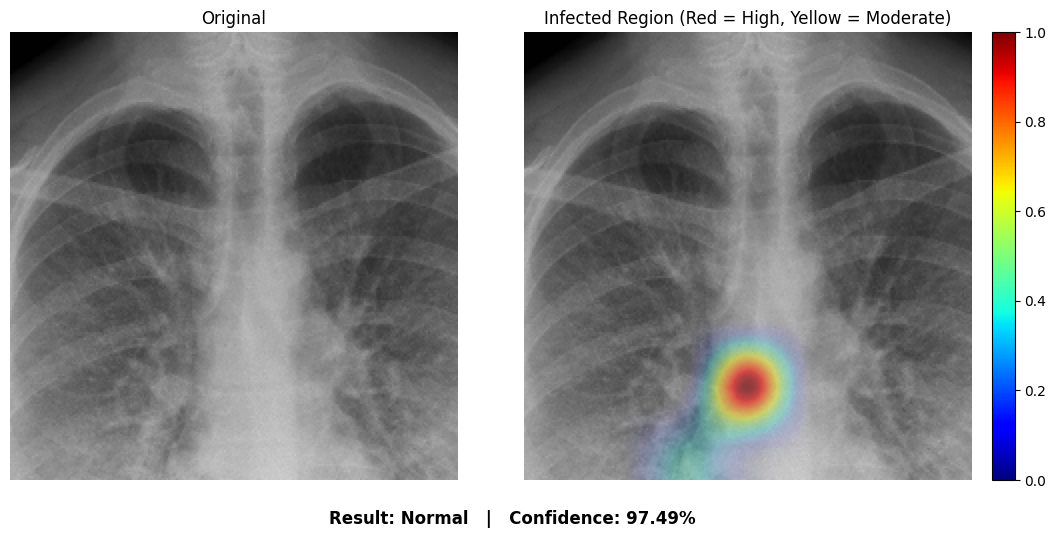

In [ ]:
"""
Grad-CAM Visualization for a DenseNet121 Binary Pneumonia Classifier
=====================================================================
Colab notebook-cell version -- just run this cell, upload an X-ray
when prompted, and it prints the report + shows the panel.

Research / educational tool. NOT a diagnostic device. Grad-CAM shows
regions correlated with the model's decision, not a confirmed
clinical finding -- always confirm with a radiologist.
"""

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.applications.densenet import preprocess_input
from google.colab import files

# --------------------------------------------------------------------------- #
# Config -- edit these two if needed
# --------------------------------------------------------------------------- #
MODEL_PATH = "/content/drive/MyDrive/LungDisease/final_model.keras"
IMG_SIZE = (224, 224)
DEFAULT_LAST_CONV = "conv5_block16_concat"


def resolve_conv_layer(model, preferred):
    """Confirm the requested layer exists; otherwise fall back to the last
    4D-output (conv-like) layer found by scanning backwards."""
    try:
        model.get_layer(preferred)
        return preferred
    except ValueError:
        print(f"[warn] Layer '{preferred}' not found, searching for a fallback...")

    for layer in reversed(model.layers):
        try:
            shape = layer.output_shape
        except AttributeError:
            continue
        if isinstance(shape, tuple) and len(shape) == 4:
            print(f"[warn] Using '{layer.name}' as the Grad-CAM target layer instead.")
            return layer.name

    raise ValueError(
        "Could not find any 4D (conv-like) layer output in the model. "
        "Grad-CAM requires a spatial feature map."
    )


def compute_gradcam(model, x, layer_name):
    """Return (cam normalized 0-1 at IMG_SIZE, raw sigmoid prediction)."""
    grad_model = tf.keras.Model(
        inputs=model.input,
        outputs=[model.get_layer(layer_name).output, model.output],
    )

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x, training=False)
        loss = preds[:, 0]  # binary sigmoid head -> single channel

    grads = tape.gradient(loss, conv_out)
    if grads is None:
        raise RuntimeError(
            "Gradient is None -- check that the chosen layer sits on the path "
            "from model input to model output."
        )

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(weights * conv_out[0], axis=-1)
    cam = tf.nn.relu(cam)

    cam_max_tf = tf.reduce_max(cam)
    cam = tf.where(cam_max_tf > 0, cam / (cam_max_tf + 1e-8), cam)
    cam = cam.numpy()

    cam = cv2.resize(cam, IMG_SIZE, interpolation=cv2.INTER_CUBIC)
    cam = np.clip(cam, 0, None)
    cam = cv2.GaussianBlur(cam, (11, 11), 0)

    cam_min, cam_max = cam.min(), cam.max()
    if cam_max - cam_min < 1e-8:
        cam = np.zeros_like(cam)  # degenerate/flat map -- don't fake structure
    else:
        cam = (cam - cam_min) / (cam_max - cam_min)

    pred_value = float(preds.numpy()[0][0])
    return cam, pred_value


def build_overlay(display_rgb, cam, max_alpha=0.65):
    """Blend heatmap onto the original image, weighted by the activation
    value itself (per-pixel alpha = cam * max_alpha). Low/zero-activation
    areas stay original grayscale; only genuinely hot regions get colored."""
    colormap = plt.get_cmap("jet")
    heat_rgb = colormap(cam)[..., :3]
    pixel_alpha = (cam * max_alpha)[..., None]
    blended = display_rgb * (1 - pixel_alpha) + heat_rgb * pixel_alpha
    return (np.clip(blended, 0, 1) * 255).astype(np.uint8)


def localize_region(cam, percentile=90.0):
    """Adaptive-threshold region finder using size-relative geometry."""
    h, w = cam.shape
    if cam.max() <= 0:
        return "No significant region", None

    thresh_val = max(np.percentile(cam, percentile), 0.3)
    mask = (cam >= thresh_val).astype(np.uint8) * 255

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return "No significant region", None

    c = max(contours, key=cv2.contourArea)
    x0, y0, bw, bh = cv2.boundingRect(c)

    roi = cam[y0:y0 + bh, x0:x0 + bw]
    ys, xs = np.mgrid[y0:y0 + bh, x0:x0 + bw]
    weight_sum = roi.sum()
    if weight_sum > 0:
        cx = float((xs * roi).sum() / weight_sum)
        cy = float((ys * roi).sum() / weight_sum)
    else:
        cx, cy = x0 + bw / 2, y0 + bh / 2

    side = "Left Lung" if cx < w / 2 else "Right Lung"
    if cy < h / 3:
        level = "Upper Lung"
    elif cy < 2 * h / 3:
        level = "Middle Lung"
    else:
        level = "Lower Lung"

    return f"{side} | {level}", (x0, y0, bw, bh)


def risk_from_confidence(label, confidence):
    if label == "Normal":
        return "No Pneumonia Pattern Detected"
    if confidence >= 95:
        return "Severe"
    if confidence >= 85:
        return "High"
    if confidence >= 70:
        return "Moderate"
    return "Low"


# --------------------------------------------------------------------------- #
# Main flow
# --------------------------------------------------------------------------- #
model = load_model(MODEL_PATH)
last_conv = resolve_conv_layer(model, DEFAULT_LAST_CONV)

print("Upload Chest X-ray...")
uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No file uploaded.")
img_path = list(uploaded.keys())[0]

img = keras_image.load_img(img_path, target_size=IMG_SIZE)
img_arr = keras_image.img_to_array(img).astype("float32")
display = np.clip(img_arr / 255.0, 0.0, 1.0)

x = preprocess_input(img_arr.copy())
x = np.expand_dims(x, 0)

cam, pred = compute_gradcam(model, x, last_conv)

label = "Pneumonia" if pred >= 0.5 else "Normal"
confidence = (pred if pred >= 0.5 else 1 - pred) * 100
risk = risk_from_confidence(label, confidence)

overlay = build_overlay(display, cam, max_alpha=0.65)

if label == "Pneumonia":
    location, bbox = localize_region(cam)
    if bbox is not None:
        x0, y0, bw, bh = bbox
        cv2.rectangle(overlay, (x0, y0), (x0 + bw, y0 + bh), (0, 255, 0), 2)
else:
    location = "N/A (Normal prediction)"

# ---- 2 images: Original + Overlay (heatmap baked in, blue removed) ---- #
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(display); axes[0].set_title("Original"); axes[0].axis("off")

axes[1].imshow(overlay)
axes[1].set_title("Infected Region (Red = High, Yellow = Moderate)")
axes[1].axis("off")

sm = plt.cm.ScalarMappable(cmap=plt.get_cmap("jet"), norm=plt.Normalize(vmin=0, vmax=1))
sm.set_array([])
fig.colorbar(sm, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()

# --- Result summary shown right under the images --- #
if label == "Pneumonia":
    summary = (
        f"Result: Pneumonia   |   Confidence: {confidence:.2f}%   |   "
        f"Risk Level: {risk}   |   Region: {location}"
    )
else:
    summary = f"Result: Normal   |   Confidence: {confidence:.2f}%"

fig.text(0.5, -0.03, summary, ha="center", va="top", fontsize=12, weight="bold")
plt.show()

print("=" * 60)
print("AI CHEST X-RAY REPORT (research prototype -- not for clinical use)")
print("=" * 60)
if label == "Normal":
    print(f"Result          : Normal")
    print(f"Confidence      : {confidence:.2f}%")
else:
    print(f"Result          : Pneumonia")
    print(f"Confidence      : {confidence:.2f}%")
    print(f"Risk Level      : {risk}")
    print(f"Affected Region : {location}")
print("=" * 60)
print("Note: Grad-CAM shows correlation with the model's decision, not a")
print("confirmed clinical finding. Always confirm with a radiologist.")

In [ ]:
os.system('ls -F')

0

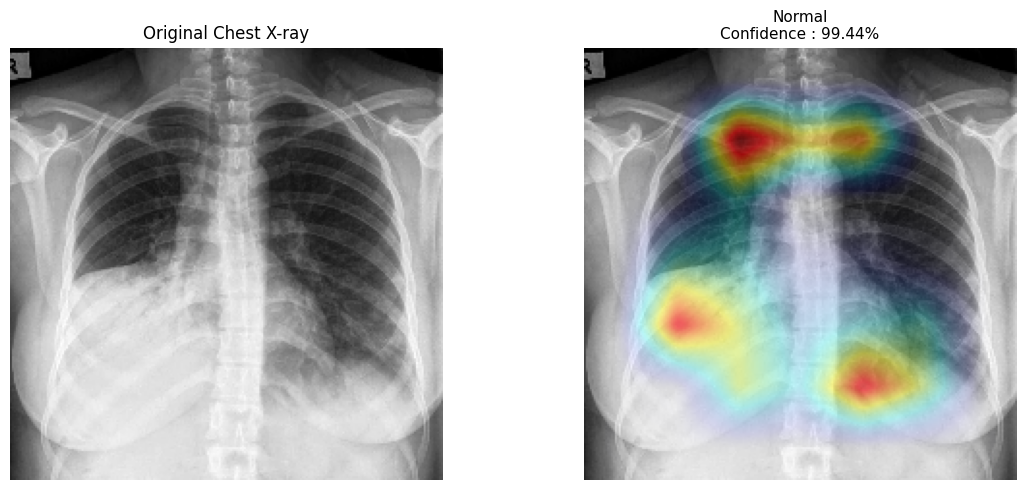

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from google.colab import files

# ==========================================================
# LOAD MODEL
# ==========================================================

model = load_model("/content/drive/MyDrive/LungDisease/final_model.keras")

IMG_SIZE = (224, 224)

# ==========================================================
# FIND LAST CONV LAYER
# ==========================================================

last_conv_layer_name = None

for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer :", last_conv_layer_name)

# ==========================================================
# UPLOAD IMAGE
# ==========================================================

uploaded = files.upload()

img_path = list(uploaded.keys())[0]

# ==========================================================
# PREPROCESS IMAGE
# ==========================================================

img = image.load_img(img_path, target_size=IMG_SIZE)

img_array = image.img_to_array(img)

original_image = img_array.astype("uint8")

img_array = np.expand_dims(img_array, axis=0)

# Same preprocessing as training
img_array = img_array / 255.0

# ==========================================================
# PREDICTION
# ==========================================================

prediction = model.predict(img_array, verbose=0)[0][0]

if prediction > 0.5:
    label = "Pneumonia"
    confidence = prediction * 100
else:
    label = "Normal"
    confidence = (1 - prediction) * 100

# ==========================================================
# GRAD-CAM
# ==========================================================

grad_model = tf.keras.models.Model(
    [model.inputs],
    [
        model.get_layer(last_conv_layer_name).output,
        model.output
    ]
)

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(img_array)

    loss = predictions[:, 0]

grads = tape.gradient(loss, conv_outputs)

pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

conv_outputs = conv_outputs[0]

heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

heatmap = tf.maximum(heatmap, 0)

heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

heatmap = heatmap.numpy()

# ==========================================================
# FIX: SUPPRESS BORDER / EDGE ARTIFACTS
# ==========================================================
# Conv layers use zero-padding, which makes the outermost cells of the
# feature map get artificially high gradients (they "see" the padding,
# not real anatomy). On chest X-rays this shows up as a fake hot spot
# glued to the image edge/corner where there's no lung tissue at all.
#
# Fix: taper the heatmap smoothly to 0 near its border using a raised-
# cosine window, BEFORE resizing/locating the hot region. This kills
# edge/corner artifacts while leaving genuine central activations intact.

def edge_taper_mask(h, w, margin_frac=0.12):
    def taper_1d(n, margin):
        m = np.ones(n, dtype="float32")
        margin = max(1, int(margin))
        ramp = 0.5 - 0.5 * np.cos(np.linspace(0, np.pi, margin))
        m[:margin] = ramp
        m[-margin:] = ramp[::-1]
        return m

    ty = taper_1d(h, int(h * margin_frac))
    tx = taper_1d(w, int(w * margin_frac))
    return np.outer(ty, tx)

taper = edge_taper_mask(heatmap.shape[0], heatmap.shape[1], margin_frac=0.12)
heatmap = heatmap * taper

# Re-normalize after tapering so the scale is still 0-1.
heatmap = heatmap / (heatmap.max() + 1e-8)

# ==========================================================
# ESTIMATE AFFECTED LUNG & REGION
# ==========================================================

heatmap_resize = cv2.resize(
    heatmap,
    (IMG_SIZE[1], IMG_SIZE[0])
)

# Smooth after resizing too, so the upsampled map doesn't have blocky
# per-cell edges that could re-introduce a hard border line.
heatmap_resize = cv2.GaussianBlur(heatmap_resize, (11, 11), 0)
heatmap_resize = heatmap_resize / (heatmap_resize.max() + 1e-8)

_, _, _, maxLoc = cv2.minMaxLoc(heatmap_resize)

x, y = maxLoc

height, width = heatmap_resize.shape

if heatmap_resize.max() <= 0:
    lung_side, lung_region = "N/A", "No significant region"
else:
    if x < width // 2:
        lung_side = "Left Lung"
    else:
        lung_side = "Right Lung"

    if y < height // 3:
        lung_region = "Upper Lung"
    elif y < 2 * height // 3:
        lung_region = "Middle Lung"
    else:
        lung_region = "Lower Lung"

# ==========================================================
# CREATE OVERLAY
# ==========================================================
# FIX: use per-pixel alpha (weighted by heatmap value) instead of a
# constant blend. A constant alpha paints jet's low-end blue across the
# WHOLE image -- including zero-activation areas -- which is misleading.
# With per-pixel alpha, only genuinely activated pixels get colored.

heatmap_uint8 = np.uint8(255 * heatmap_resize)
heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)  # keep everything in RGB

pixel_alpha = (heatmap_resize * 0.65)[..., None]  # 0 where heatmap=0 -> no tint
overlay = original_image.astype("float32") * (1 - pixel_alpha) + heatmap_color.astype("float32") * pixel_alpha
overlay = np.clip(overlay, 0, 255).astype("uint8")

# ==========================================================
# RISK LEVEL
# ==========================================================

if label == "Normal":
    risk = "No Pneumonia Pattern Detected"
elif confidence >= 90:
    risk = "High"
elif confidence >= 70:
    risk = "Moderate"
else:
    risk = "Low"

# ==========================================================
# DISPLAY
# ==========================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image.astype("uint8"))
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay)
if label == "Pneumonia":
    plt.title(
        f"{label}\n"
        f"Confidence : {confidence:.2f}%\n"
        f"Heatmap Focus : {lung_side} | {lung_region}",
        fontsize=11
    )
else:
    plt.title(
        f"{label}\n"
        f"Confidence : {confidence:.2f}%",
        fontsize=11
    )
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================================
# FINAL REPORT
# ==========================================================

print("=" * 50)
print("          LUNG DISEASE REPORT")
print("=" * 50)
if label == "Normal":
    print(f"Prediction        : {label}")
    print(f"Confidence Score  : {confidence:.2f}%")
else:
    print(f"Prediction        : {label}")
    print(f"Confidence Score  : {confidence:.2f}%")
    print(f"Risk Level        : {risk}")
    print(f"Heatmap Focus     : {lung_side} | {lung_region}")
print("=" * 50)

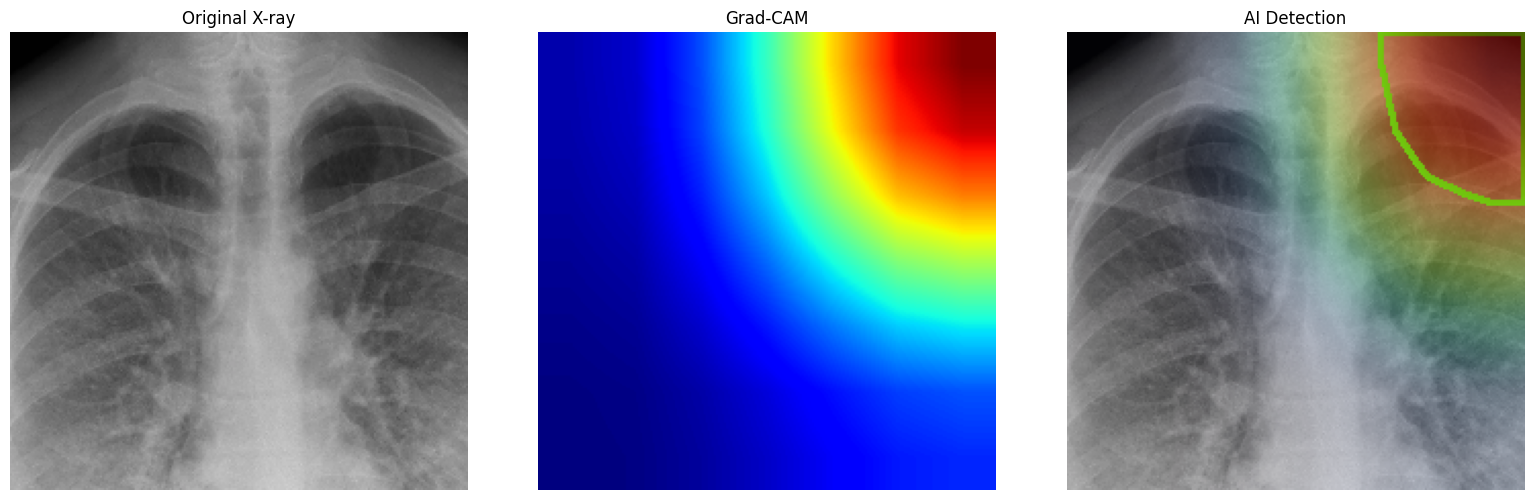

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from google.colab import files

# ==========================================================
# LOAD MODEL
# ==========================================================

MODEL_PATH = "/content/drive/MyDrive/LungDisease/final_model.keras"

model = load_model(MODEL_PATH)

IMG_SIZE = (224,224)

LAST_CONV_LAYER = "conv5_block16_concat"

# ==========================================================
# UPLOAD IMAGE
# ==========================================================

uploaded = files.upload()

img_path = list(uploaded.keys())[0]

# ==========================================================
# PREPROCESS IMAGE
# ==========================================================

img = image.load_img(
    img_path,
    target_size=IMG_SIZE
)

img_array = image.img_to_array(img)

original_image = img_array.astype("uint8")

img_array = img_array.astype("float32") / 255.0

img_array = np.expand_dims(img_array, axis=0)

# ==========================================================
# MODEL PREDICTION
# ==========================================================

prediction = model.predict(
    img_array,
    verbose=0
)[0][0]

THRESHOLD = 0.50

if prediction >= THRESHOLD:

    label = "Pneumonia"

    confidence = prediction * 100

else:

    label = "Normal"

    confidence = (1-prediction) * 100

print("Prediction :",label)
print("Confidence :",round(confidence,2),"%")

# ==========================================================
# GRAD MODEL
# ==========================================================

grad_model = tf.keras.models.Model(

    inputs=model.input,

    outputs=[

        model.get_layer(LAST_CONV_LAYER).output,

        model.output

    ]

)

# ==========================================================
# GRAD-CAM
# ==========================================================

with tf.GradientTape() as tape:

    conv_output, \
    predictions = grad_model(img_array)

    loss = predictions[:,0]

grads = tape.gradient(

    loss,

    conv_output

)

pooled_grads = tf.reduce_mean(

    grads,

    axis=(0,1,2)

)

conv_output = conv_output[0]

heatmap = tf.reduce_sum(

    pooled_grads * conv_output,

    axis=-1

)

heatmap = tf.maximum(

    heatmap,

    0

)

heatmap = heatmap / (

    tf.reduce_max(heatmap) + 1e-8

)

heatmap = heatmap.numpy()

# ==========================================================
# REMOVE EDGE ARTIFACTS
# ==========================================================

heatmap = cv2.GaussianBlur(

    heatmap,

    (11,11),

    0

)

heatmap = cv2.resize(

    heatmap,

    IMG_SIZE

)

heatmap = heatmap / (

    heatmap.max()+1e-8

)

print("Grad-CAM Generated Successfully")


# ==========================================================
# PUBLICATION QUALITY VISUALIZATION
# ==========================================================

# Heatmap
heatmap_uint8 = np.uint8(255 * heatmap)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_TURBO
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# ==========================================================
# FIND HOTTEST REGION
# ==========================================================

threshold = np.percentile(heatmap, 90)

mask = (heatmap >= threshold).astype(np.uint8)

ys, xs = np.where(mask == 1)

if len(xs) > 0:

    center_x = int(np.mean(xs))
    center_y = int(np.mean(ys))

else:

    center_x = IMG_SIZE[0] // 2
    center_y = IMG_SIZE[1] // 2

# ==========================================================
# LEFT / RIGHT LUNG
# ==========================================================

if center_x < IMG_SIZE[1] // 2:
    lung_side = "Left Lung"
else:
    lung_side = "Right Lung"

# ==========================================================
# UPPER / MIDDLE / LOWER
# ==========================================================

if center_y < IMG_SIZE[0] // 3:
    lung_region = "Upper Lung"

elif center_y < 2 * IMG_SIZE[0] // 3:
    lung_region = "Middle Lung"

else:
    lung_region = "Lower Lung"

# ==========================================================
# DRAW CONTOUR
# ==========================================================

contours, _ = cv2.findContours(
    mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

overlay = original_image.copy()

if len(contours) > 0:

    largest = max(
        contours,
        key=cv2.contourArea
    )

    cv2.drawContours(
        overlay,
        [largest],
        -1,
        (0,255,0),
        2
    )

# ==========================================================
# HEATMAP OVERLAY
# ==========================================================

alpha = (heatmap * 0.60)[..., np.newaxis]

overlay = (
    overlay.astype(np.float32) * (1 - alpha)
    +
    heatmap_color.astype(np.float32) * alpha
)

overlay = np.clip(
    overlay,
    0,
    255
).astype(np.uint8)

# ==========================================================
# RISK LEVEL
# ==========================================================

if label == "Normal":

    risk = "No Pneumonia Detected"

else:

    if confidence >= 95:

        risk = "Severe"

    elif confidence >= 90:

        risk = "High"

    elif confidence >= 75:

        risk = "Moderate"

    else:

        risk = "Low"

# ==========================================================
# DISPLAY
# ==========================================================

plt.figure(figsize=(16,5))

plt.subplot(1,3,1)
plt.imshow(original_image)
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(heatmap,cmap="jet")
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title("AI Detection")
plt.axis("off")

plt.tight_layout()
plt.show()



# ==========================================================
# FINAL  REPORT
# ==========================================================

if prediction >= 0.5:
    label = "Pneumonia"
    confidence = prediction * 100
else:
    label = "Normal"
    confidence = (1 - prediction) * 100

# Risk Level
if label == "Normal":
    risk = "No Risk"

elif confidence >= 95:
    risk = "Very High"

elif confidence >= 90:
    risk = "High"

elif confidence >= 80:
    risk = "Moderate"

elif confidence >= 70:
    risk = "Low"

else:
    risk = "Very Low"

print("=" * 50)
print("      AI CHEST X-RAY ANALYSIS REPORT")
print("=" * 50)
print(f"Prediction      : {label}")
print(f"Confidence      : {confidence:.2f}%")
print(f"Risk Level      : {risk}")
print("=" * 50)